# Eksplorasi PCD

Membandingkan beberapa metode enhancement dan segmentasi untuk memilih pipeline PCD sementara di Progress 2. Pemilihan dilakukan secara visual pada 9 foto train (3 per kelas), termasuk kasus sulit dari EDA: objek bening, objek yang warnanya mirip lantai, dan latar bertekstur. Evaluasi dengan IoU/Dice terhadap GT mask dilakukan di Progress 3.

In [7]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from core.config import DATA_DIR, METADATA_CSV, REPORTS_DIR
from core.image import load_image, resize_43
from pcd import processing
from pcd.pipeline import run_pcd, segment

FIGURES = REPORTS_DIR / "pcd"
FIGURES.mkdir(parents=True, exist_ok=True)

SAMPLE = [
    "PL-J-003", "PL-F-004", "PL-M-003",
    "KT-J-002", "KT-M-003", "KT-F-002",
    "KD-F-007", "KD-J-003", "KD-M-004",
]

photos = pd.read_csv(METADATA_CSV)
sample = photos[photos["object_id"].isin(SAMPLE) & (photos["view"] == "atas")].set_index("object_id").loc[SAMPLE]
assert (sample["split"] == "train").all(), "eksplorasi hanya boleh memakai foto train"
images = {object_id: resize_43(load_image(DATA_DIR / path)) for object_id, path in sample["raw_path"].items()}
sample[["label", "subtype", "member"]]

,label,subtype,member
object_id,,,
PL-J-003,plastik,gelas cup,Jefri
PL-F-004,plastik,bungkus snack,Farhan
PL-M-003,plastik,wadah/tutup,Mafaza
KT-J-002,kertas,diremas,Jefri
KT-M-003,kertas,diremas,Mafaza
KT-F-002,kertas,dilipat/sobek,Farhan
KD-F-007,kardus,kotak utuh,Farhan
KD-J-003,kardus,kotak utuh,Jefri
KD-M-004,kardus,kotak utuh,Mafaza


In [9]:
def to_rgb(image: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def outline(image: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """Gambar tepi mask berwarna hijau di atas citra."""
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return cv2.drawContours(image.copy(), contours, -1, (0, 255, 0), 2)


def show_grid(columns: dict, file_name: str, object_ids: list = SAMPLE) -> None:
    """Satu baris per foto; setiap kolom adalah fungsi object_id -> citra BGR."""
    fig, axes = plt.subplots(len(object_ids), len(columns), figsize=(2.3 * len(columns), 2.6 * len(object_ids)))
    for row, object_id in zip(axes, object_ids):
        for column, (title, make) in enumerate(columns.items()):
            row[column].imshow(to_rgb(make(object_id)))
            row[column].set_title(f"{object_id}, {title}" if column == 0 else title, fontsize=8)
            row[column].axis("off")
    fig.tight_layout()
    fig.savefig(FIGURES / file_name, dpi=110)

## 1. Enhancement

CLAHE menaikkan kontras lokal pada kanal L tanpa mengubah warna. Gamma mengubah kecerahan secara global: nilai di bawah 1 mencerahkan dan di atas 1 menggelapkan.

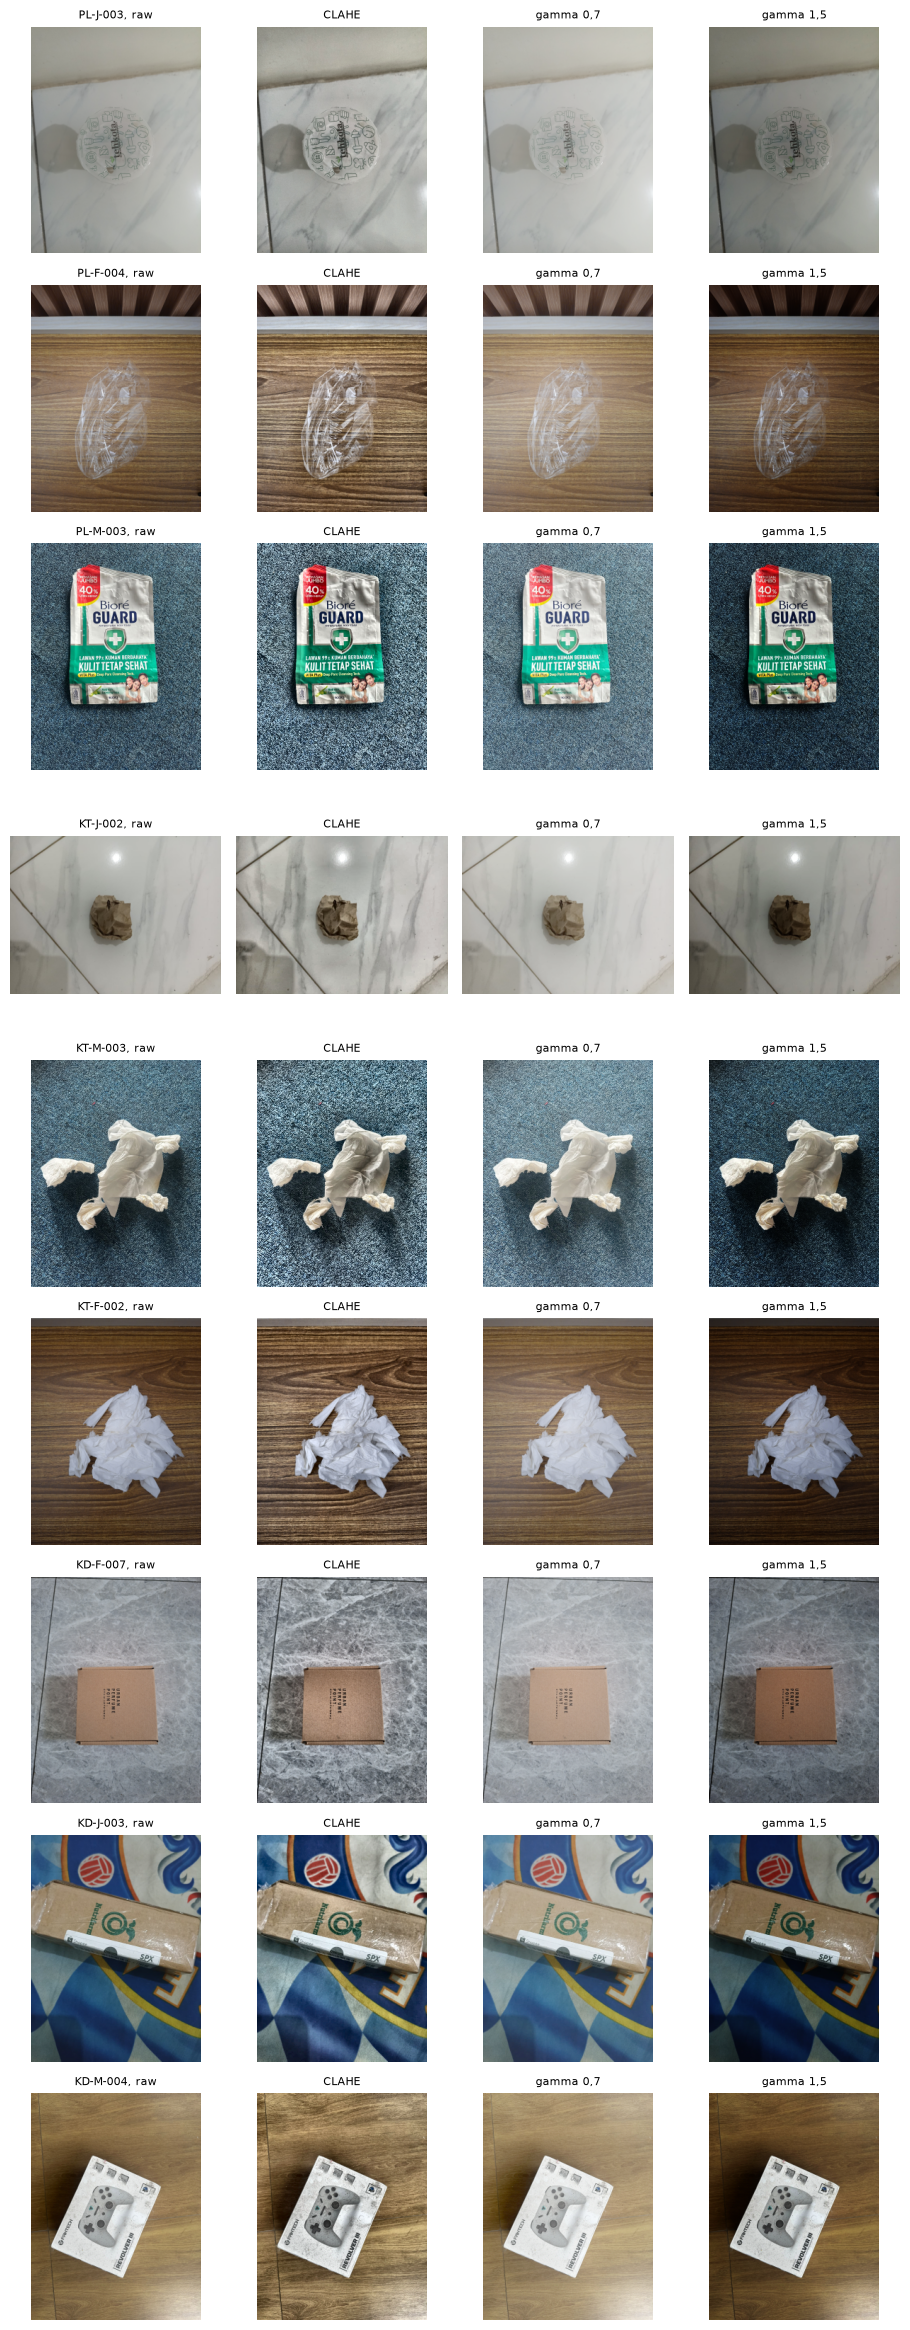

In [10]:
ENHANCEMENTS = {
    "raw": lambda image: image,
    "CLAHE": processing.clahe,
    "gamma 0,7": lambda image: processing.gamma_correction(image, 0.7),
    "gamma 1,5": lambda image: processing.gamma_correction(image, 1.5),
}
show_grid(
    {title: lambda object_id, enhance=enhance: enhance(images[object_id]) for title, enhance in ENHANCEMENTS.items()},
    "pcd_enhancement.png",
)

## 2. Segmentasi

Setiap metode memakai citra CLAHE. Otsu didahului Gaussian blur agar tekstur halus tidak ikut terpisah. Kolom gabungan memakai mask Otsu saturation sebagai tebakan awal GrabCut, kalau tebakan itu tidak wajar (luasnya terlalu kecil atau besar, atau banyak menempel di tepi foto), GrabCut mulai dari kotak di tengah. Garis hijau adalah tepi mask setelah dirapikan dengan morfologi (opening, closing, komponen besar disimpan, lubang diisi).

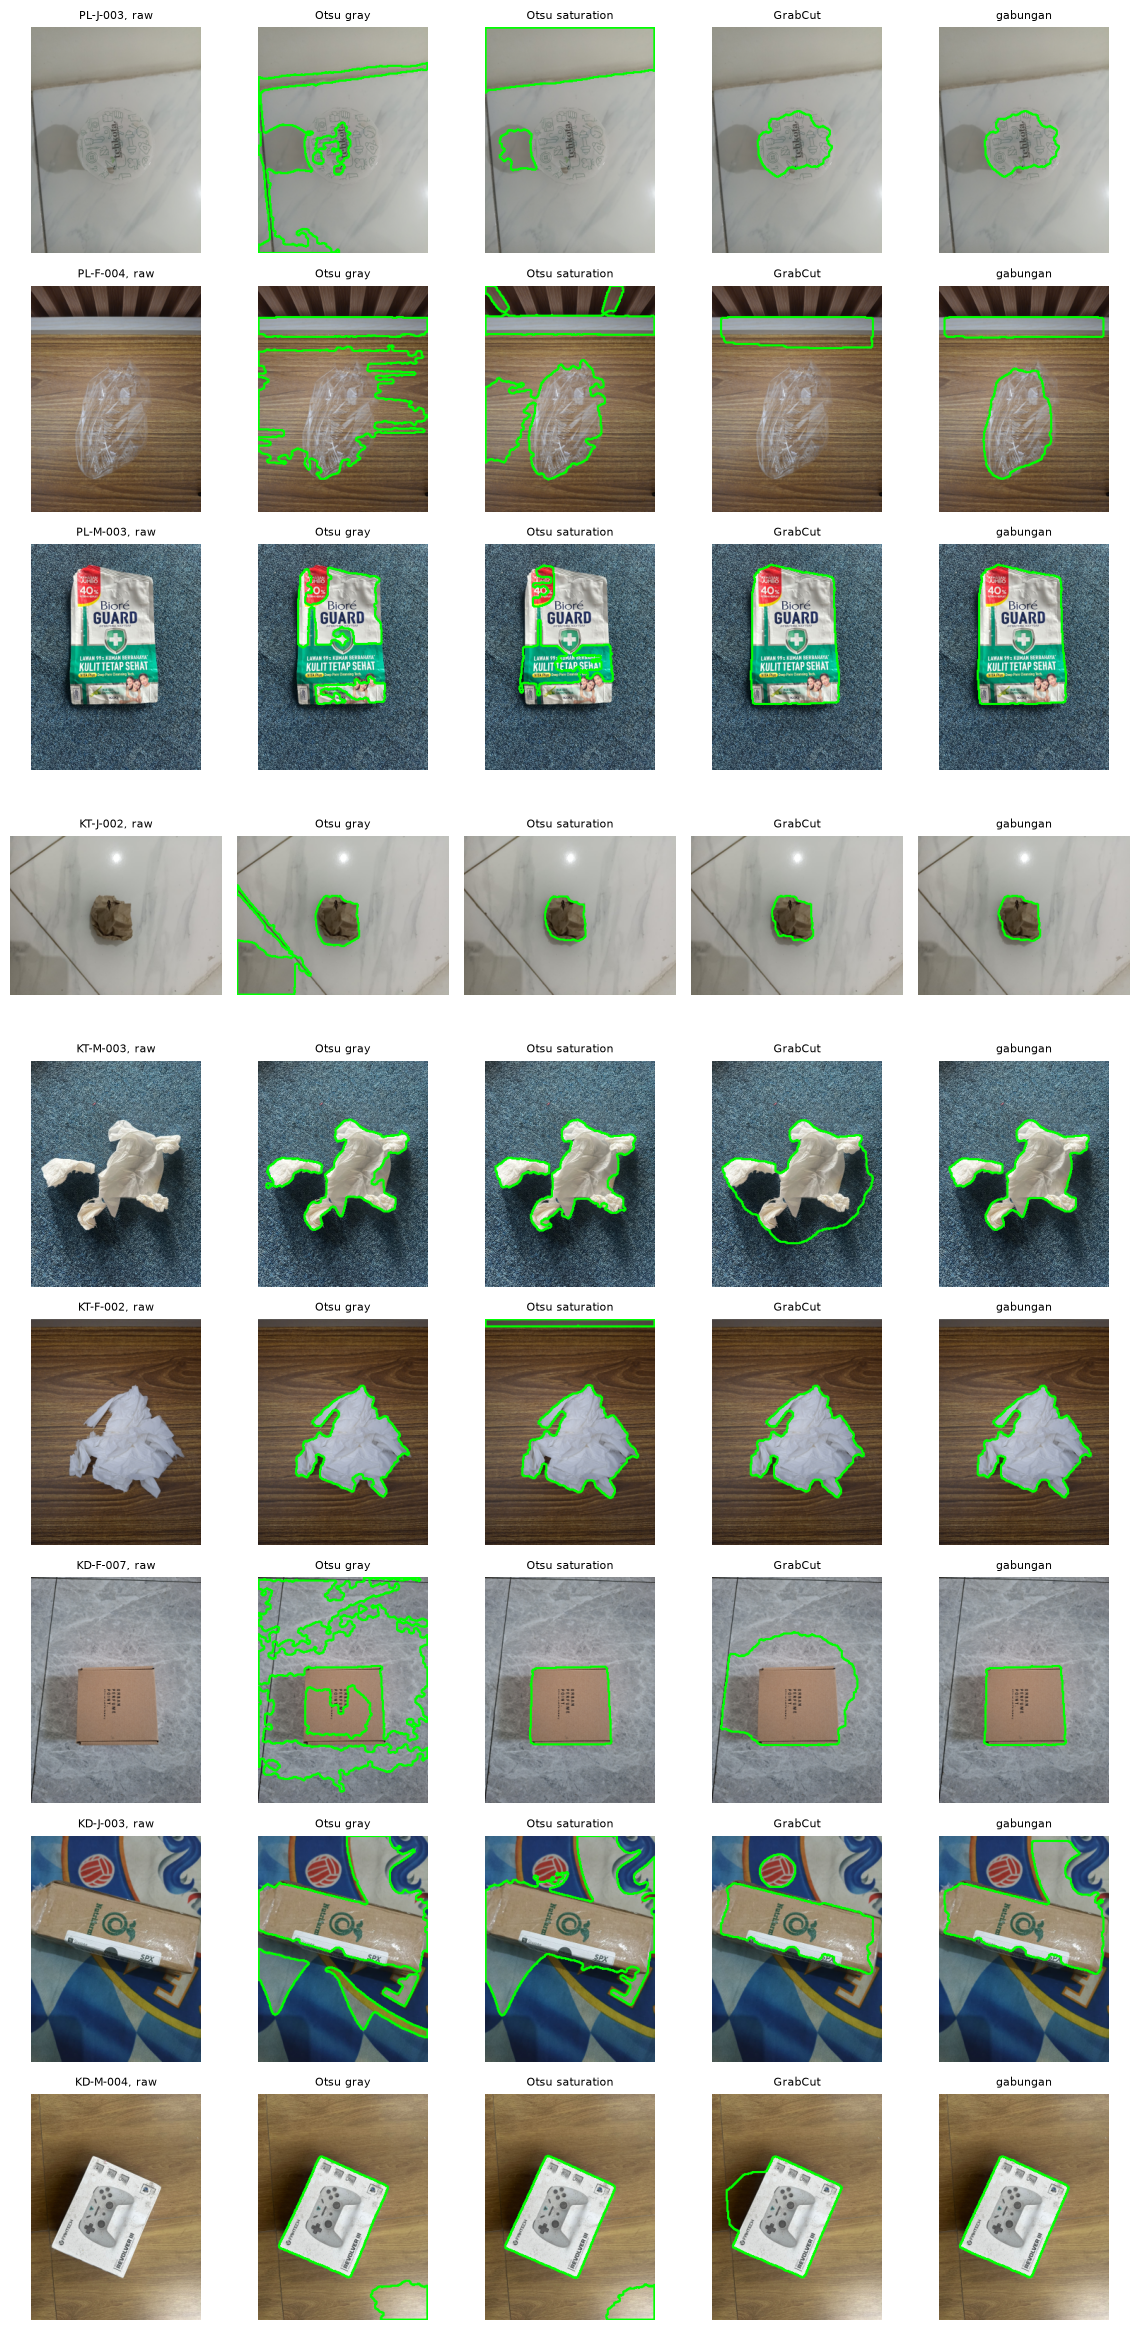

In [11]:
SEGMENTATIONS = {
    "Otsu gray": lambda image: processing.otsu_mask(processing.blur(image), "gray"),
    "Otsu saturation": lambda image: processing.otsu_mask(processing.blur(image), "saturation"),
    "GrabCut": processing.grabcut_mask,
    "gabungan": segment,
}

enhanced = {object_id: processing.clahe(image) for object_id, image in images.items()}
cleaned = {
    (object_id, method): processing.clean_mask(make_mask(enhanced[object_id]))
    for object_id in SAMPLE
    for method, make_mask in SEGMENTATIONS.items()
}

show_grid(
    {"raw": lambda object_id: images[object_id]}
    | {
        method: lambda object_id, method=method: outline(images[object_id], cleaned[(object_id, method)])
        for method in SEGMENTATIONS
    },
    "pcd_segmentation.png",
)

Hasil penilaian visual:

| Foto | Otsu gray | Otsu saturation | GrabCut | Gabungan |
|---|---|---|---|---|
| PL-J-003 gelas bening, marmer | gagal | gagal | berhasil | berhasil |
| PL-F-004 plastik bening, kayu | gagal | sebagian | gagal | sebagian |
| PL-M-003 bungkus, karpet | sebagian | sebagian | berhasil | berhasil |
| KT-J-002 kertas cokelat, marmer | gagal | berhasil | berhasil | berhasil |
| KT-M-003 tisu, karpet | berhasil | berhasil | gagal | berhasil |
| KT-F-002 tisu, kayu | berhasil | sebagian | berhasil | berhasil |
| KD-F-007 kardus, marmer abu-abu | gagal | berhasil | gagal | berhasil |
| KD-J-003 kardus, kain bermotif | gagal | gagal | sebagian | sebagian |
| KD-M-004 kotak putih, kayu | sebagian | sebagian | sebagian | berhasil |
| **Jumlah berhasil** | **2** | **3** | **4** | **7** |

Otsu gray paling sering gagal karena lantai terang punya kecerahan yang mirip objek. Otsu saturation bekerja baik pada latar polos yang pucat, tetapi gagal pada latar berwarna dan objek bening. GrabCut dengan kotak di tengah lebih tahan pada latar ramai, tetapi sering ikut mengambil bayangan atau lantai. Gabungan keduanya paling banyak berhasil: Otsu saturation memberi tebakan awal yang dekat dengan objek, GrabCut memperbaikinya, dan kalau tebakannya tidak wajar (PL-J-003), GrabCut kembali ke kotak di tengah.

Kegagalan yang masih tersisa: PL-F-004 ikut mengambil pinggiran dinding di atas foto, dan KD-J-003 ikut mengambil sebagian kain bermotif. Objek bening di latar terang tetap menjadi kasus tersulit karena warnanya meneruskan warna lantai. Ini dicoba diperbaiki di Progress 3, misalnya dengan segmentasi berbasis tepi.

Pipeline sementara: CLAHE, Otsu saturation sebagai tebakan awal, GrabCut, morfologi, lalu masking. CLAHE dipakai karena GrabCut pada citra CLAHE lebih sering berhasil daripada pada citra raw. Gamma tidak dipakai karena hanya mengubah kecerahan secara global.

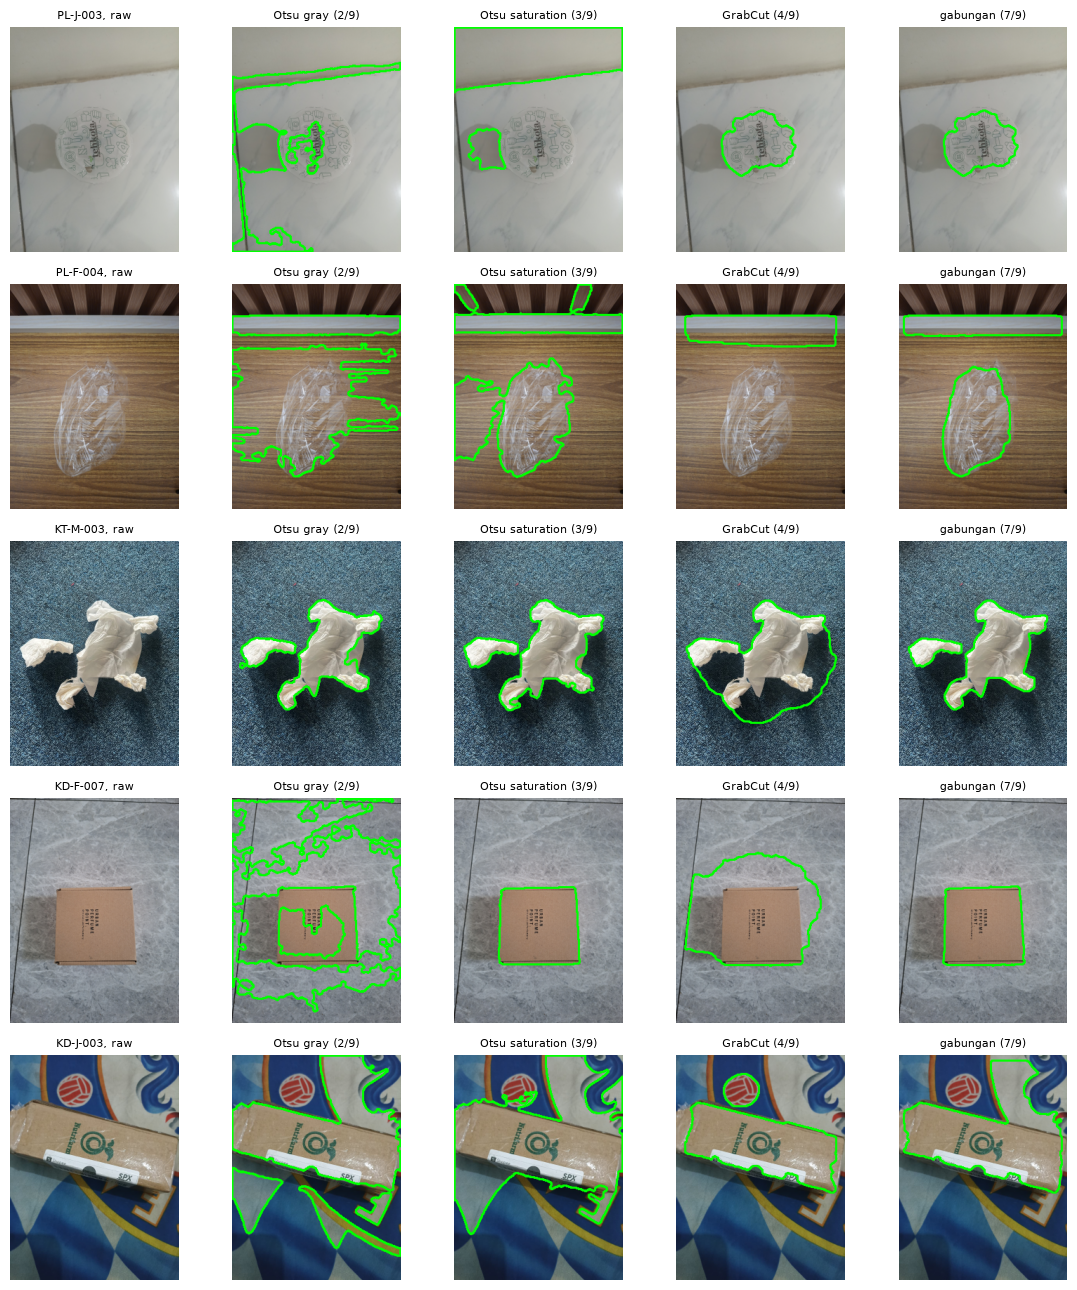

In [14]:
SLIDE_SAMPLE = ["PL-J-003", "PL-F-004", "KT-M-003", "KD-F-007", "KD-J-003"]
SUCCESS = {"Otsu gray": 2, "Otsu saturation": 3, "GrabCut": 4, "gabungan": 7}

show_grid(
    {"raw": lambda object_id: images[object_id]}
    | {
        f"{method} ({SUCCESS[method]}/{len(SAMPLE)})": (
            lambda object_id, method=method: outline(images[object_id], cleaned[(object_id, method)])
        )
        for method in SEGMENTATIONS
    },
    "pcd_segmentation_slide.png",
    SLIDE_SAMPLE,
)

## 3. Langkah pipeline terpilih

Contoh satu foto dari awal sampai akhir. Crop ROI tidak dipakai di output `segmented` karena ukurannya harus tetap sama dengan input, tetapi ditampilkan untuk menunjukkan area objek.

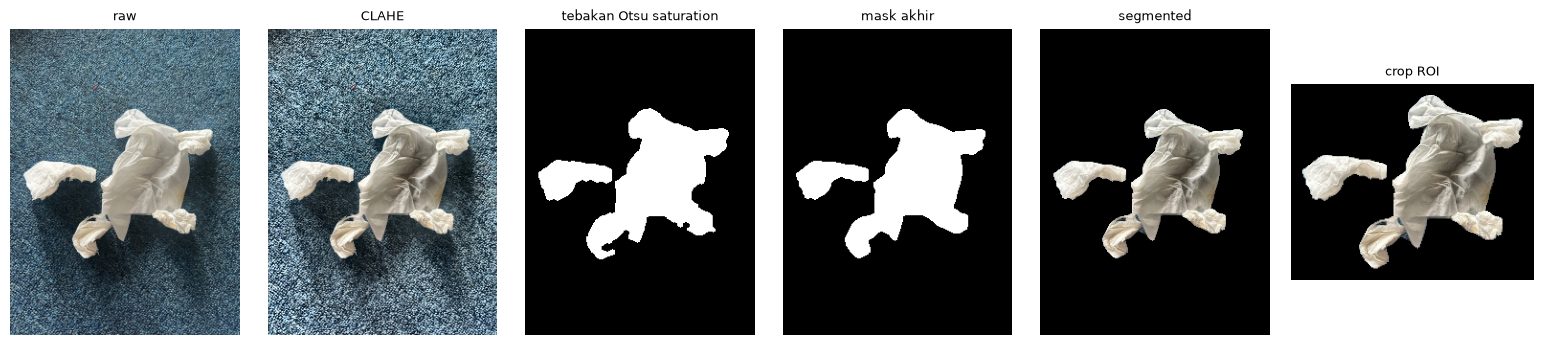

In [15]:
STEP_SAMPLE = "KT-M-003"

image = images[STEP_SAMPLE]
result = run_pcd(image)
seed = processing.clean_mask(processing.otsu_mask(processing.blur(result["enhanced"]), "saturation"))
steps = {
    "raw": image,
    "CLAHE": result["enhanced"],
    "tebakan Otsu saturation": cv2.cvtColor(seed, cv2.COLOR_GRAY2BGR),
    "mask akhir": cv2.cvtColor(result["mask"], cv2.COLOR_GRAY2BGR),
    "segmented": result["segmented"],
    "crop ROI": processing.crop_roi(result["segmented"], result["mask"]),
}

fig, axes = plt.subplots(1, len(steps), figsize=(2.6 * len(steps), 3.4))
for ax, (title, step) in zip(axes, steps.items()):
    ax.imshow(to_rgb(step))
    ax.set_title(title, fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES / "pcd_steps.png", dpi=130)